# Model Evaluation — Employee Attrition (Corrected)

This notebook uses **the exact seven estimator configurations and preprocessing steps from `04_Model_Training_Final_Fixed_Updated.ipynb`**. It repeats training on the same stratified training split so it can run independently, and selects the best model using **mean 5-fold cross-validation F1-score**, not test-set results. The held-out test set is used only for final evaluation. No deployed model file is overwritten.

**Run from `backend/notebooks`** after completing the previous notebooks and generating `backend/data/employee_attrition_selected.csv`.

In [1]:
import json
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
N_SPLITS = 5
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, precision_recall_curve


In [2]:
data_candidates = [
    Path("../data/employee_attrition_selected.csv"),
    Path("backend/data/employee_attrition_selected.csv"),
    Path("/mnt/data/employee_attrition_selected.csv"),
]

data_path = next((path for path in data_candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "employee_attrition_selected.csv not found. "
        "Run this notebook from backend/notebooks or update data_candidates."
    )

df = pd.read_csv(data_path)

if "Attrition" not in df.columns:
    raise ValueError("The dataset must contain the target column 'Attrition'.")

df = df.dropna(subset=["Attrition"]).copy()
X = df.drop(columns=["Attrition"])
y = df["Attrition"].map({"Yes": 1, "No": 0})

if y.isna().any():
    raise ValueError("Attrition must contain only 'Yes' and 'No' values.")

y = y.astype(int)

print("Dataset path:", data_path.resolve())
print("Dataset shape:", df.shape)
print("Number of input features:", X.shape[1])
print("\nTarget distribution:")
print(df["Attrition"].value_counts())
print("\nTarget proportions:")
print(df["Attrition"].value_counts(normalize=True).round(4))
display(df.head())

Dataset path: C:\Users\kanga\Downloads\employee-attrition-prediction\backend\data\employee_attrition_selected.csv
Dataset shape: (1470, 33)
Number of input features: 32

Target distribution:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Target proportions:
Attrition
No     0.8388
Yes    0.1612
Name: proportion, dtype: float64


,Age,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,JobInvolvement,JobLevel,...,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,CompanyExperienceRatio,PromotionFrequency,IncomePerYearExperience,SatisfactionScore,RoleTenureRatio,Attrition
0,41,Travel_Rarely,Sales,1,2,Life Sciences,2,Female,3,2,...,6,4,0,5,0.750000,0.000,749.125000,2.00,0.666667,Yes
1,49,Travel_Frequently,Research & Development,8,1,Life Sciences,3,Male,2,2,...,10,7,1,7,1.000000,0.100,513.000000,3.00,0.700000,No
2,37,Travel_Rarely,Research & Development,2,2,Other,4,Male,2,1,...,0,0,0,0,0.000000,0.000,298.571429,3.00,0.000000,Yes
3,33,Travel_Frequently,Research & Development,3,4,Life Sciences,4,Female,3,1,...,8,7,3,0,1.000000,0.375,363.625000,3.25,0.875000,No
4,27,Travel_Rarely,Research & Development,2,1,Medical,1,Male,3,1,...,2,2,2,2,0.333333,1.000,578.000000,2.50,1.000000,No


In [3]:
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = X.select_dtypes(exclude=["object", "category", "bool"]).columns.tolist()

print("Categorical features:", categorical_features)
print("\nNumerical features:", numeric_features)

Categorical features: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Numerical features: ['Age', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'CompanyExperienceRatio', 'PromotionFrequency', 'IncomePerYearExperience', 'SatisfactionScore', 'RoleTenureRatio']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining target distribution:")
print(y_train.value_counts())
print("\nTest target distribution:")
print(y_test.value_counts())

Training samples: 1176
Testing samples: 294

Training target distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Test target distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


In [5]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ],
    remainder="drop",
)

print("Preprocessor configured.")

Preprocessor configured.


In [6]:
model_estimators = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE,
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
    ),
    "Gaussian Naive Bayes": GaussianNB(),
}

# Each estimator gets its own pipeline. The preprocessor is fitted inside
# each training fold during cross-validation.
models = {
    name: Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("model", estimator),
        ]
    )
    for name, estimator in model_estimators.items()
}

print(f"Models to compare: {len(models)}")
for index, name in enumerate(models, start=1):
    print(f"{index}. {name}")

Models to compare: 7
1. Logistic Regression
2. Random Forest
3. SVM
4. Gradient Boosting
5. Decision Tree
6. KNN
7. Gaussian Naive Bayes


In [7]:
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)


def fit_pipeline(model, model_name, X_fit, y_fit):
    """Fit a pipeline, applying balanced sample weights to Gradient Boosting."""
    if model_name == "Gradient Boosting":
        counts = y_fit.value_counts()
        sample_weights = y_fit.map({
            class_label: len(y_fit) / (2.0 * count)
            for class_label, count in counts.items()
        }).to_numpy()

        model.fit(
            X_fit,
            y_fit,
            model__sample_weight=sample_weights
        )
    else:
        model.fit(X_fit, y_fit)

    return model


def calculate_metrics(y_true, y_pred, y_prob=None):
    """Calculate the four required classification metrics."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
    }


cv_metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
]

cv_results = {}
fitted_models = {}

for model_name, base_model in models.items():
    fold_scores = {
        metric: [] for metric in cv_metric_names
    }

    for train_indices, validation_indices in cv.split(X_train, y_train):
        X_fold_train = X_train.iloc[train_indices]
        X_fold_valid = X_train.iloc[validation_indices]

        y_fold_train = y_train.iloc[train_indices]
        y_fold_valid = y_train.iloc[validation_indices]

        fold_model = clone(base_model)

        fit_pipeline(
            fold_model,
            model_name,
            X_fold_train,
            y_fold_train
        )

        fold_predictions = fold_model.predict(X_fold_valid)

        fold_metrics = calculate_metrics(
            y_fold_valid,
            fold_predictions
        )

        for metric in cv_metric_names:
            fold_scores[metric].append(fold_metrics[metric])

    mean_cv_metrics = {
        metric: float(np.mean(scores))
        for metric, scores in fold_scores.items()
    }

    cv_results[model_name] = mean_cv_metrics

    # Refit the model using the complete training set.
    final_model = clone(base_model)

    fit_pipeline(
        final_model,
        model_name,
        X_train,
        y_train
    )

    fitted_models[model_name] = final_model

    print(f"\nModel: {model_name}")

    for metric in cv_metric_names:
        print(f"{metric}: {mean_cv_metrics[metric]:.4f}")


# Display the cross-validation comparison table.
cv_results_df = pd.DataFrame(cv_results).T
cv_results_df.index.name = "Model"

display(cv_results_df.round(4))


Model: Logistic Regression
Accuracy: 0.7729
Precision: 0.3934
Recall: 0.7158
F1 Score: 0.5055

Model: Random Forest
Accuracy: 0.8673
Precision: 0.9250
Recall: 0.2053
F1 Score: 0.3257

Model: SVM
Accuracy: 0.8384
Precision: 0.5056
Recall: 0.6000
F1 Score: 0.5458

Model: Gradient Boosting
Accuracy: 0.8444
Precision: 0.5171
Recall: 0.5316
F1 Score: 0.5226

Model: Decision Tree
Accuracy: 0.7968
Precision: 0.3734
Recall: 0.3737
F1 Score: 0.3706

Model: KNN
Accuracy: 0.8529
Precision: 0.7197
Recall: 0.1579
F1 Score: 0.2541

Model: Gaussian Naive Bayes
Accuracy: 0.6793
Precision: 0.3183
Recall: 0.7526
F1 Score: 0.4402


,Accuracy,Precision,Recall,F1 Score
Model,,,,
Logistic Regression,0.7729,0.3934,0.7158,0.5055
Random Forest,0.8673,0.9250,0.2053,0.3257
SVM,0.8384,0.5056,0.6000,0.5458
Gradient Boosting,0.8444,0.5171,0.5316,0.5226
Decision Tree,0.7968,0.3734,0.3737,0.3706
KNN,0.8529,0.7197,0.1579,0.2541
Gaussian Naive Bayes,0.6793,0.3183,0.7526,0.4402


## Cross-validation comparison and model selection

The models are fitted independently in each training fold. Gradient Boosting sample weights are recalculated **within each fold**, avoiding full-training-set class weights during cross-validation. The winner is selected using the highest mean CV F1-score.

In [8]:
best_model_name = max(cv_results, key=lambda name: cv_results[name]["F1 Score"])
print("Selected model (highest mean CV F1):", best_model_name)
print("Mean CV F1:", round(cv_results[best_model_name]["F1 Score"], 4))

Selected model (highest mean CV F1): SVM
Mean CV F1: 0.5458


## Held-out test-set evaluation

The test set is never used for choosing the model. **ROC-AUC** measures ranking performance; **average precision (AP)** summarizes the precision-recall curve (reported as PR-AUC/AP).

In [9]:
predictions = {}
probabilities = {}
test_rows = {}

for name, model in fitted_models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    predictions[name] = pred
    probabilities[name] = prob
    test_rows[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC (AP)": average_precision_score(y_test, prob),
    }

cv_evaluation = (cv_results_df.reset_index()
                 .sort_values("F1 Score", ascending=False)
                 .reset_index(drop=True))
test_evaluation = (pd.DataFrame([{"Model": name, **metrics}
                                 for name, metrics in test_rows.items()])
                   .sort_values("F1 Score", ascending=False)
                   .reset_index(drop=True))

print("Cross-validation comparison:")
display(cv_evaluation.round(4))
print("Held-out test comparison:")
display(test_evaluation.round(4))
print("CV-selected model:", best_model_name)
print("Its test metrics:")
display(test_evaluation[test_evaluation["Model"] == best_model_name].round(4))

Cross-validation comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,0.8384,0.5056,0.6000,0.5458
1,Gradient Boosting,0.8444,0.5171,0.5316,0.5226
2,Logistic Regression,0.7729,0.3934,0.7158,0.5055
3,Gaussian Naive Bayes,0.6793,0.3183,0.7526,0.4402
4,Decision Tree,0.7968,0.3734,0.3737,0.3706
5,Random Forest,0.8673,0.9250,0.2053,0.3257
6,KNN,0.8529,0.7197,0.1579,0.2541


Held-out test comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC (AP)
0,SVM,0.8197,0.4516,0.5957,0.5138,0.8105,0.5368
1,Logistic Regression,0.7721,0.3864,0.7234,0.5037,0.8188,0.5535
2,Gradient Boosting,0.7959,0.3818,0.4468,0.4118,0.7774,0.4670
3,Gaussian Naive Bayes,0.6871,0.2897,0.6596,0.4026,0.7070,0.3027
4,Decision Tree,0.7619,0.2444,0.2340,0.2391,0.5482,0.1797
5,Random Forest,0.8435,0.5556,0.1064,0.1786,0.8105,0.4442
6,KNN,0.8231,0.3077,0.0851,0.1333,0.6064,0.2630


CV-selected model: SVM
Its test metrics:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC (AP)
0,SVM,0.8197,0.4516,0.5957,0.5138,0.8105,0.5368


## Confusion matrices

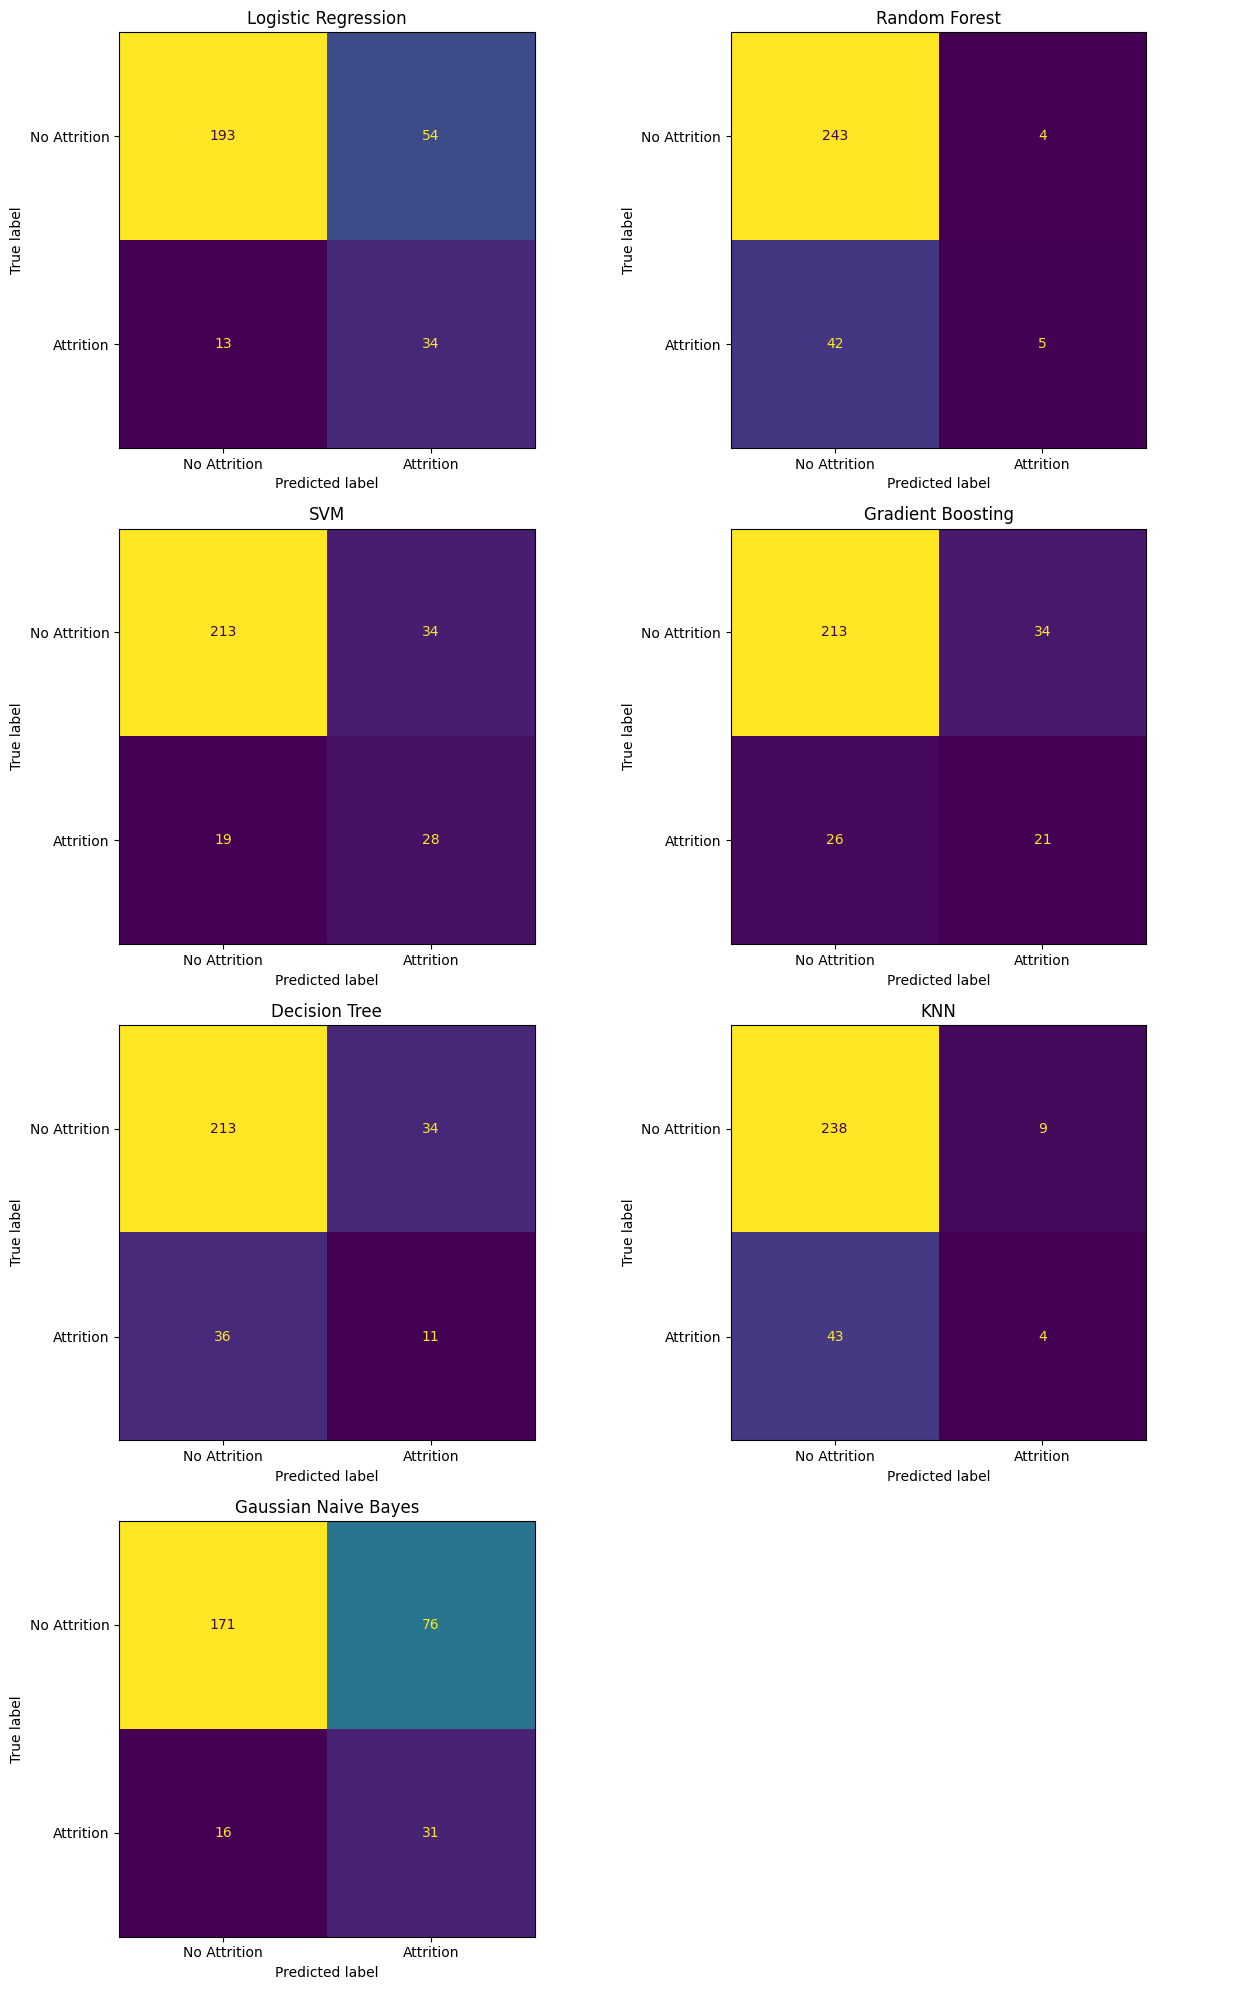

In [10]:
fig, axes = plt.subplots(4, 2, figsize=(13, 20))
axes = axes.ravel()

for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, pred),
        display_labels=["No Attrition", "Attrition"]
    ).plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(name)

for ax in axes[len(predictions):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


## ROC curves

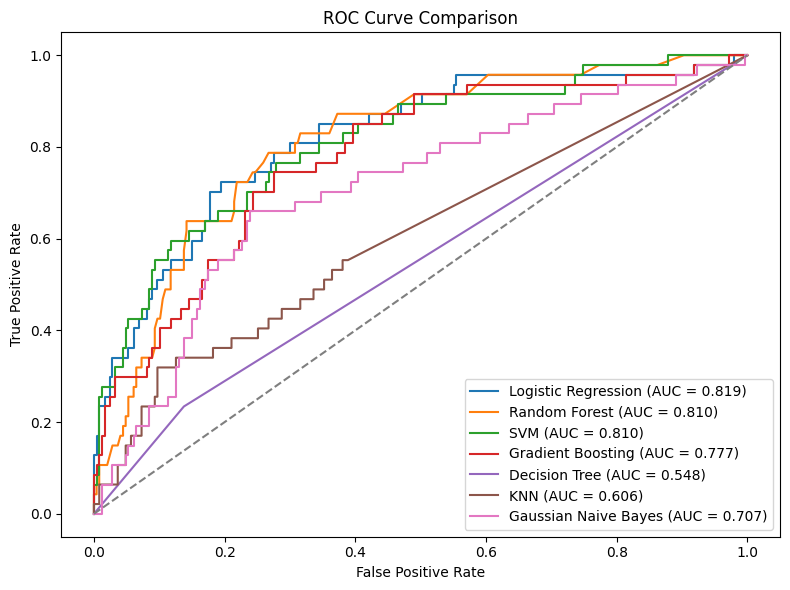

In [11]:
plt.figure(figsize=(8, 6))
for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()


## Precision–Recall curves

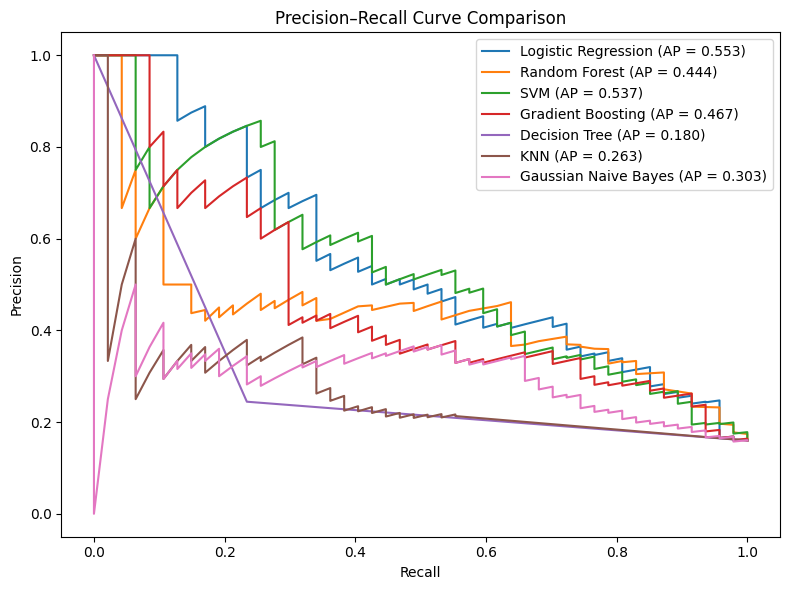

In [12]:
plt.figure(figsize=(8, 6))
for name, prob in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    pr_auc = average_precision_score(y_test, prob)
    plt.plot(recall, precision, label=f"{name} (AP = {pr_auc:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()


## Classification reports

In [13]:
for name, pred in predictions.items():
    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)
    print(classification_report(
        y_test, pred,
        target_names=["No Attrition", "Attrition"],
        zero_division=0
    ))



Logistic Regression
              precision    recall  f1-score   support

No Attrition       0.94      0.78      0.85       247
   Attrition       0.39      0.72      0.50        47

    accuracy                           0.77       294
   macro avg       0.66      0.75      0.68       294
weighted avg       0.85      0.77      0.80       294


Random Forest
              precision    recall  f1-score   support

No Attrition       0.85      0.98      0.91       247
   Attrition       0.56      0.11      0.18        47

    accuracy                           0.84       294
   macro avg       0.70      0.55      0.55       294
weighted avg       0.81      0.84      0.80       294


SVM
              precision    recall  f1-score   support

No Attrition       0.92      0.86      0.89       247
   Attrition       0.45      0.60      0.51        47

    accuracy                           0.82       294
   macro avg       0.68      0.73      0.70       294
weighted avg       0.84      0.82

## Save evaluation results

Save CSV and JSON reports in `backend/models/` without replacing any model artifacts. The JSON records the CV-selected model and its metrics. The evaluation notebook refits models for reporting but **does not deploy them**.

In [14]:
output_dir = Path("../models")
output_dir.mkdir(parents=True, exist_ok=True)

cv_evaluation.to_csv(output_dir / "model_comparison_cv.csv", index=False)
test_evaluation.to_csv(output_dir / "model_comparison_test.csv", index=False)

summary = {
    "selection_method": "Highest mean F1 from 5-fold stratified cross-validation on training data",
    "selected_model": best_model_name,
    "selected_model_cv_metrics": cv_results[best_model_name],
    "selected_model_test_metrics": test_rows[best_model_name],
    "models_compared": list(fitted_models.keys()),
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "note": "Evaluation only; does not overwrite deployed model artifacts."
}
with open(output_dir / "model_evaluation_summary.json", "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

print("Saved evaluation reports to:", output_dir.resolve())
print("model_comparison_cv.csv")
print("model_comparison_test.csv")
print("model_evaluation_summary.json")

Saved evaluation reports to: C:\Users\kanga\Downloads\employee-attrition-prediction\backend\models
model_comparison_cv.csv
model_comparison_test.csv
model_evaluation_summary.json
